# 03. Feature Engineering

## 1. Objective

This notebook examines and validates the financial and temporal
features constructed from the FDIC bank-quarter panel.

## 2. Feature Groups

- Profitability and financial condition
- Asset quality and loss reserves
- Capital and funding structure
- Temporal changes and asset growth
- Data quality and extreme-value indicators

## 3. Input Dataset

data/processed/v3/bank_quarter_features_v3.parquet

## 4. Output

A validated feature dataset for subsequent model development.

In [1]:
import polars as pl
import numpy as np
from pathlib import Path

# Locate project directory
current_dir = Path.cwd()

if (current_dir / "data").exists():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / "data").exists():
    PROJECT_ROOT = current_dir.parent
else:
    raise FileNotFoundError("Cannot locate project directory.")

# Define paths
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

feature_path = PROCESSED_DIR / "v3" / "bank_quarter_features_v3.parquet"

# Load feature dataset
features = pl.read_parquet(feature_path)

print("Dataset loaded successfully!")
print("Shape:", features.shape)
print("Number of banks:", features["CERT"].n_unique())
print("Number of columns:", len(features.columns))

Dataset loaded successfully!
Shape: (1663876, 36)
Number of banks: 24053
Number of columns: 36


In [2]:
from pathlib import Path

# Project root directory
project_root = Path.cwd()

# If notebook is running from the notebooks folder, move one level up
if project_root.name == "notebooks":
    project_root = project_root.parent

# Save all figures in reports/figures
figure_dir = project_root / "reports" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

print("Figures will be saved to:", figure_dir)

Figures will be saved to: c:\Users\ADMIN\OneDrive\BFT65B_Final_Project\reports\figures


In [3]:
# Check duplicate bank-quarter observations
duplicate_count = (
    features
    .group_by(["CERT", "REPORT_DATE"])
    .len()
    .filter(pl.col("len") > 1)
    .height
)

print("=== DATA QUALITY CHECK ===")
print("Total observations:", features.height)
print("Duplicate bank-quarter groups:", duplicate_count)

=== DATA QUALITY CHECK ===
Total observations: 1663876
Duplicate bank-quarter groups: 0


In [4]:
# Calculate missing values and missing percentages

total_rows = features.height

missing_summary = pl.DataFrame({
    "Variable": features.columns,
    "Missing_Count": [
        features[col].null_count()
        for col in features.columns
    ]
})

missing_summary = (
    missing_summary
    .with_columns(
        (
            pl.col("Missing_Count") / total_rows * 100
        ).round(4).alias("Missing_Percentage")
    )
    .filter(pl.col("Missing_Count") > 0)
    .sort("Missing_Count", descending=True)
)

print("=== COMPLETE MISSING VALUE ANALYSIS ===")
print(missing_summary)
print("\nTotal variables with missing values:", missing_summary.height)

=== COMPLETE MISSING VALUE ANALYSIS ===
shape: (20, 3)
┌────────────────────┬───────────────┬────────────────────┐
│ Variable           ┆ Missing_Count ┆ Missing_Percentage │
│ ---                ┆ ---           ┆ ---                │
│ str                ┆ i64           ┆ f64                │
╞════════════════════╪═══════════════╪════════════════════╡
│ FIRST_FAILURE_DATE ┆ 1575146       ┆ 94.6673            │
│ FAILURE_Q_INDEX    ┆ 1575146       ┆ 94.6673            │
│ PREV_NETINC_YTD    ┆ 431452        ┆ 25.9305            │
│ PREV_QUARTER       ┆ 427873        ┆ 25.7154            │
│ FINAL_LABEL        ┆ 55797         ┆ 3.3534             │
│ …                  ┆ …             ┆ …                  │
│ EQUITY_TO_ASSETS   ┆ 4080          ┆ 0.2452             │
│ NPL_TO_ASSETS      ┆ 2502          ┆ 0.1504             │
│ NCLNLS             ┆ 2499          ┆ 0.1502             │
│ DEP                ┆ 1             ┆ 0.0001             │
│ DEPOSITS_TO_ASSETS ┆ 1             ┆ 0.0001

In [5]:
# Missing value rates by year

missing_by_year = (
    features
    .group_by("YEAR")
    .agg([
        pl.len().alias("Total_Observations"),

        pl.col("QUARTERLY_NETINC")
          .null_count()
          .alias("Missing_NETINC"),

        pl.col("PREV_NETINC_YTD")
          .null_count()
          .alias("Missing_PREV_NETINC"),

        pl.col("PREV_QUARTER")
          .null_count()
          .alias("Missing_PREV_QUARTER"),

        pl.col("FINAL_LABEL")
          .null_count()
          .alias("Missing_FINAL_LABEL")
    ])
    .with_columns([
        (pl.col("Missing_NETINC") /
         pl.col("Total_Observations") * 100)
        .round(2).alias("NETINC_Missing_Rate"),

        (pl.col("Missing_PREV_NETINC") /
         pl.col("Total_Observations") * 100)
        .round(2).alias("PREV_NETINC_Missing_Rate"),

        (pl.col("Missing_PREV_QUARTER") /
         pl.col("Total_Observations") * 100)
        .round(2).alias("PREV_QUARTER_Missing_Rate"),

        (pl.col("Missing_FINAL_LABEL") /
         pl.col("Total_Observations") * 100)
        .round(2).alias("FINAL_LABEL_Missing_Rate")
    ])
    .sort("YEAR")
)

print(missing_by_year)

shape: (42, 10)
┌──────┬────────────┬────────────┬────────────┬───┬────────────┬───────────┬───────────┬───────────┐
│ YEAR ┆ Total_Obse ┆ Missing_NE ┆ Missing_PR ┆ … ┆ NETINC_Mis ┆ PREV_NETI ┆ PREV_QUAR ┆ FINAL_LAB │
│ ---  ┆ rvations   ┆ TINC       ┆ EV_NETINC  ┆   ┆ sing_Rate  ┆ NC_Missin ┆ TER_Missi ┆ EL_Missin │
│ i32  ┆ ---        ┆ ---        ┆ ---        ┆   ┆ ---        ┆ g_Rate    ┆ ng_Rate   ┆ g_Rate    │
│      ┆ u32        ┆ u32        ┆ u32        ┆   ┆ f64        ┆ ---       ┆ ---       ┆ ---       │
│      ┆            ┆            ┆            ┆   ┆            ┆ f64       ┆ f64       ┆ f64       │
╞══════╪════════════╪════════════╪════════════╪═══╪════════════╪═══════════╪═══════════╪═══════════╡
│ 1984 ┆ 71752      ┆ 1598       ┆ 18956      ┆ … ┆ 2.23       ┆ 26.42     ┆ 25.54     ┆ 1.56      │
│ 1985 ┆ 71925      ┆ 659        ┆ 18593      ┆ … ┆ 0.92       ┆ 25.85     ┆ 25.72     ┆ 1.61      │
│ 1986 ┆ 72136      ┆ 404        ┆ 18491      ┆ … ┆ 0.56       ┆ 25.63     

In [6]:
# Investigate missing quarterly net income

missing_netinc = features.filter(
    pl.col("QUARTERLY_NETINC").is_null()
)

print("=== MISSING QUARTERLY NET INCOME ===")
print("Total missing:", missing_netinc.height)

print("\nNETINC missing:", 
      missing_netinc["NETINC"].null_count())

print("\nPREV_NETINC_YTD missing:",
      missing_netinc["PREV_NETINC_YTD"].null_count())

print("\nPREV_QUARTER missing:",
      missing_netinc["PREV_QUARTER"].null_count())

print("\nSample observations:")
print(
    missing_netinc.select([
        "CERT",
        "REPORT_DATE",
        "QUARTER",
        "NETINC",
        "PREV_NETINC_YTD",
        "PREV_QUARTER",
        "QUARTERLY_NETINC"
    ]).head(15)
)

=== MISSING QUARTERLY NET INCOME ===
Total missing: 9896

NETINC missing: 4624

PREV_NETINC_YTD missing: 9617

PREV_QUARTER missing: 6038

Sample observations:
shape: (15, 7)
┌───────┬─────────────┬─────────┬─────────┬─────────────────┬──────────────┬──────────────────┐
│ CERT  ┆ REPORT_DATE ┆ QUARTER ┆ NETINC  ┆ PREV_NETINC_YTD ┆ PREV_QUARTER ┆ QUARTERLY_NETINC │
│ ---   ┆ ---         ┆ ---     ┆ ---     ┆ ---             ┆ ---          ┆ ---              │
│ i64   ┆ date        ┆ i8      ┆ f64     ┆ f64             ┆ i8           ┆ f64              │
╞═══════╪═════════════╪═════════╪═════════╪═════════════════╪══════════════╪══════════════════╡
│ 9538  ┆ 1984-03-31  ┆ 1       ┆ null    ┆ null            ┆ null         ┆ null             │
│ 9538  ┆ 1984-06-30  ┆ 2       ┆ 282.0   ┆ null            ┆ 1            ┆ null             │
│ 9538  ┆ 1984-09-30  ┆ 3       ┆ null    ┆ 282.0           ┆ 2            ┆ null             │
│ 9538  ┆ 1984-12-31  ┆ 4       ┆ 403.0   ┆ null         

In [7]:
# Classify missing quarterly net income

missing_netinc_audit = (
    features
    .filter(pl.col("QUARTERLY_NETINC").is_null())
    .with_columns(
        pl.when(pl.col("NETINC").is_null())
        .then(pl.lit("1. Missing current NETINC"))

        .when(pl.col("QUARTER") == 1)
        .then(pl.lit("2. First quarter calculation"))

        .when(
            pl.col("PREV_QUARTER").is_null()
            | (pl.col("PREV_QUARTER") != pl.col("QUARTER") - 1)
        )
        .then(pl.lit("3. Missing consecutive previous quarter"))

        .when(pl.col("PREV_NETINC_YTD").is_null())
        .then(pl.lit("4. Missing previous YTD NETINC"))

        .otherwise(pl.lit("5. Other"))
        .alias("MISSING_REASON")
    )
)

reason_summary = (
    missing_netinc_audit
    .group_by("MISSING_REASON")
    .agg(pl.len().alias("Observations"))
    .sort("MISSING_REASON")
)

print("=== QUARTERLY NET INCOME MISSING REASONS ===")
print(reason_summary)

print(
    "\nTotal:",
    reason_summary["Observations"].sum()
)

=== QUARTERLY NET INCOME MISSING REASONS ===
shape: (3, 2)
┌─────────────────────────────────┬──────────────┐
│ MISSING_REASON                  ┆ Observations │
│ ---                             ┆ ---          │
│ str                             ┆ u32          │
╞═════════════════════════════════╪══════════════╡
│ 1. Missing current NETINC       ┆ 4624         │
│ 3. Missing consecutive previou… ┆ 4731         │
│ 4. Missing previous YTD NETINC  ┆ 541          │
└─────────────────────────────────┴──────────────┘

Total: 9896


In [8]:
# Check reporting quarters in the final years

year_quarter_summary = (
    features
    .group_by(["YEAR", "QUARTER"])
    .agg(
        pl.len().alias("Observations"),
        pl.col("CERT").n_unique().alias("Unique_Banks")
    )
    .filter(pl.col("YEAR") >= 2023)
    .sort(["YEAR", "QUARTER"])
)

print(year_quarter_summary)

shape: (10, 4)
┌──────┬─────────┬──────────────┬──────────────┐
│ YEAR ┆ QUARTER ┆ Observations ┆ Unique_Banks │
│ ---  ┆ ---     ┆ ---          ┆ ---          │
│ i32  ┆ i8      ┆ u32          ┆ u32          │
╞══════╪═════════╪══════════════╪══════════════╡
│ 2023 ┆ 1       ┆ 4740         ┆ 4740         │
│ 2023 ┆ 2       ┆ 4714         ┆ 4714         │
│ 2023 ┆ 3       ┆ 4686         ┆ 4686         │
│ 2023 ┆ 4       ┆ 4658         ┆ 4658         │
│ 2024 ┆ 1       ┆ 4640         ┆ 4640         │
│ 2024 ┆ 2       ┆ 4610         ┆ 4610         │
│ 2024 ┆ 3       ┆ 4589         ┆ 4589         │
│ 2024 ┆ 4       ┆ 4560         ┆ 4560         │
│ 2025 ┆ 1       ┆ 4536         ┆ 4536         │
│ 2025 ┆ 2       ┆ 4494         ┆ 4494         │
└──────┴─────────┴──────────────┴──────────────┘


## 5. Missing Value Analysis

### 5.1 Quarterly Net Income

A total of 9,896 observations have missing `QUARTERLY_NETINC`.

The missing values are classified into three categories:

- Missing current NETINC: 4,624 observations.
- Missing consecutive previous quarter: 4,731 observations.
- Missing previous YTD NETINC: 541 observations.

Quarterly net income is calculated from year-to-date net income only when the required consecutive quarterly observations are available. Missing values are retained rather than replaced with zero or estimated from non-consecutive quarters.

### 5.2 Reporting Period Coverage

The dataset covers 1984 Q1 to 2025 Q2.

The final year contains only two reporting quarters. Therefore, annual comparisons of missing-value rates should account for differences in quarterly coverage.

### 5.3 Treatment Decision

- Retain missing values in the engineered features.
- Do not automatically impute missing financial values with zero.
- Apply imputation, if required, using training data only during model development.
- Exclude censored observations from standard binary classification training.
- Exclude variables containing future failure information from predictive features.

In [9]:
# Select important financial features
financial_vars = [
    "ROA",
    "EQUITY_TO_ASSETS",
    "DEPOSITS_TO_ASSETS",
    "NPL_TO_ASSETS",
    "ALLOWANCE_TO_ASSETS",
    "ASSET_QOQ_GROWTH"
]

# Descriptive statistics
financial_summary = (
    features
    .select(financial_vars)
    .describe()
)

print("=== FINANCIAL FEATURES: DESCRIPTIVE STATISTICS ===")
print(financial_summary)

=== FINANCIAL FEATURES: DESCRIPTIVE STATISTICS ===
shape: (9, 7)
┌────────────┬─────────────┬──────────────┬──────────────┬─────────────┬─────────────┬─────────────┐
│ statistic  ┆ ROA         ┆ EQUITY_TO_AS ┆ DEPOSITS_TO_ ┆ NPL_TO_ASSE ┆ ALLOWANCE_T ┆ ASSET_QOQ_G │
│ ---        ┆ ---         ┆ SETS         ┆ ASSETS       ┆ TS          ┆ O_ASSETS    ┆ ROWTH       │
│ str        ┆ f64         ┆ ---          ┆ ---          ┆ ---         ┆ ---         ┆ ---         │
│            ┆             ┆ f64          ┆ f64          ┆ f64         ┆ f64         ┆ f64         │
╞════════════╪═════════════╪══════════════╪══════════════╪═════════════╪═════════════╪═════════════╡
│ count      ┆ 1.663876e6  ┆ 1.659796e6   ┆ 1.663875e6   ┆ 1.661374e6  ┆ 1.659786e6  ┆ 1.639791e6  │
│ null_count ┆ 0.0         ┆ 4080.0       ┆ 1.0          ┆ 2502.0      ┆ 4090.0      ┆ 24085.0     │
│ mean       ┆ 0.881806    ┆ 10.689215    ┆ 84.043133    ┆ 1.099456    ┆ 0.859199    ┆ 3.263083    │
│ std        ┆ 3.817057   

In [10]:
percentiles = [0.01, 0.05, 0.50, 0.95, 0.99]

percentile_rows = []

for col in financial_vars:
    values = features.select([
        pl.col(col).quantile(p).alias(f"P{int(p * 100):02d}")
        for p in percentiles
    ]).to_dicts()[0]

    percentile_rows.append({
        "VARIABLE": col,
        **values
    })

percentile_table = pl.DataFrame(percentile_rows)

with pl.Config(tbl_rows=20, tbl_cols=10, tbl_width_chars=180):
    print(percentile_table)

shape: (6, 6)
┌─────────────────────┬────────────┬───────────┬───────────┬───────────┬───────────┐
│ VARIABLE            ┆ P01        ┆ P05       ┆ P50       ┆ P95       ┆ P99       │
│ ---                 ┆ ---        ┆ ---       ┆ ---       ┆ ---       ┆ ---       │
│ str                 ┆ f64        ┆ f64       ┆ f64       ┆ f64       ┆ f64       │
╞═════════════════════╪════════════╪═══════════╪═══════════╪═══════════╪═══════════╡
│ ROA                 ┆ -5.51018   ┆ -1.055494 ┆ 0.973229  ┆ 2.155644  ┆ 4.13727   │
│ EQUITY_TO_ASSETS    ┆ 0.43036    ┆ 4.963355  ┆ 9.225514  ┆ 18.25523  ┆ 64.61331  │
│ DEPOSITS_TO_ASSETS  ┆ 2.882343   ┆ 67.4157   ┆ 87.177215 ┆ 92.934552 ┆ 96.336722 │
│ NPL_TO_ASSETS       ┆ 0.0        ┆ 0.0       ┆ 0.533612  ┆ 3.9216    ┆ 8.742309  │
│ ALLOWANCE_TO_ASSETS ┆ 0.0        ┆ 0.101986  ┆ 0.749119  ┆ 1.847011  ┆ 3.415122  │
│ ASSET_QOQ_GROWTH    ┆ -11.557072 ┆ -5.22196  ┆ 1.171116  ┆ 11.769681 ┆ 34.755993 │
└─────────────────────┴────────────┴───────────┴───

In [11]:
# Thresholds used for diagnostic purposes only.
# These are NOT automatic deletion or winsorization thresholds.

outlier_conditions = {
    "ROA_BELOW_P01": pl.col("ROA") < -5.51018,
    "ROA_ABOVE_P99": pl.col("ROA") > 4.13727,

    "EQUITY_RATIO_BELOW_P01": pl.col("EQUITY_TO_ASSETS") < 0.43036,
    "EQUITY_RATIO_ABOVE_P99": pl.col("EQUITY_TO_ASSETS") > 64.61331,

    "DEPOSITS_RATIO_ABOVE_100": pl.col("DEPOSITS_TO_ASSETS") > 100,

    "NPL_RATIO_ABOVE_P99": pl.col("NPL_TO_ASSETS") > 8.742309,
    "ALLOWANCE_RATIO_ABOVE_P99": pl.col("ALLOWANCE_TO_ASSETS") > 3.415122,

    "ASSET_GROWTH_BELOW_P01": pl.col("ASSET_QOQ_GROWTH") < -11.557072,
    "ASSET_GROWTH_ABOVE_P99": pl.col("ASSET_QOQ_GROWTH") > 34.755993
}

total_rows = features.height

outlier_summary = []

for name, condition in outlier_conditions.items():
    count = features.filter(condition).height

    outlier_summary.append({
        "CONDITION": name,
        "COUNT": count,
        "PERCENT": round(count / total_rows * 100, 4)
    })

outlier_table = pl.DataFrame(outlier_summary)

print("=== EXTREME OBSERVATION SUMMARY ===")
print(outlier_table)

=== EXTREME OBSERVATION SUMMARY ===
shape: (9, 3)
┌───────────────────────────┬───────┬─────────┐
│ CONDITION                 ┆ COUNT ┆ PERCENT │
│ ---                       ┆ ---   ┆ ---     │
│ str                       ┆ i64   ┆ f64     │
╞═══════════════════════════╪═══════╪═════════╡
│ ROA_BELOW_P01             ┆ 16639 ┆ 1.0     │
│ ROA_ABOVE_P99             ┆ 16640 ┆ 1.0001  │
│ EQUITY_RATIO_BELOW_P01    ┆ 16599 ┆ 0.9976  │
│ EQUITY_RATIO_ABOVE_P99    ┆ 16599 ┆ 0.9976  │
│ DEPOSITS_RATIO_ABOVE_100  ┆ 5473  ┆ 0.3289  │
│ NPL_RATIO_ABOVE_P99       ┆ 16615 ┆ 0.9986  │
│ ALLOWANCE_RATIO_ABOVE_P99 ┆ 16599 ┆ 0.9976  │
│ ASSET_GROWTH_BELOW_P01    ┆ 16399 ┆ 0.9856  │
│ ASSET_GROWTH_ABOVE_P99    ┆ 16399 ┆ 0.9856  │
└───────────────────────────┴───────┴─────────┘


In [12]:
# Inspect observations where deposits exceed total assets

high_deposit_ratio = (
    features
    .filter(pl.col("DEPOSITS_TO_ASSETS") > 100)
    .select([
        "CERT",
        "REPORT_DATE",
        "ASSET",
        "DEP",
        "EQ",
        "DEPOSITS_TO_ASSETS",
        "ROA",
        "FAILURE_LABEL",
        "FINAL_LABEL"
    ])
)

print("Number of observations:", high_deposit_ratio.height)
print("Number of unique banks:", high_deposit_ratio["CERT"].n_unique())

print("\n=== TOP 15 OBSERVATIONS ===")
print(
    high_deposit_ratio
    .sort("DEPOSITS_TO_ASSETS", descending=True)
    .head(15)
)

Number of observations: 5473
Number of unique banks: 1500

=== TOP 15 OBSERVATIONS ===
shape: (15, 9)
┌───────┬─────────────┬────────┬──────────┬───┬─────────────┬────────────┬────────────┬────────────┐
│ CERT  ┆ REPORT_DATE ┆ ASSET  ┆ DEP      ┆ … ┆ DEPOSITS_TO ┆ ROA        ┆ FAILURE_LA ┆ FINAL_LABE │
│ ---   ┆ ---         ┆ ---    ┆ ---      ┆   ┆ _ASSETS     ┆ ---        ┆ BEL        ┆ L          │
│ i64   ┆ date        ┆ i64    ┆ f64      ┆   ┆ ---         ┆ f64        ┆ ---        ┆ ---        │
│       ┆             ┆        ┆          ┆   ┆ f64         ┆            ┆ i8         ┆ i8         │
╞═══════╪═════════════╪════════╪══════════╪═══╪═════════════╪════════════╪════════════╪════════════╡
│ 32048 ┆ 1989-03-31  ┆ 48872  ┆ 434862.0 ┆ … ┆ 889.797839  ┆ -103.49979 ┆ 1          ┆ 1          │
│       ┆             ┆        ┆          ┆   ┆             ┆ 7          ┆            ┆            │
│ 32048 ┆ 1988-12-31  ┆ 57277  ┆ 442100.0 ┆ … ┆ 771.863051  ┆ -135.25925 ┆ 1          ┆ 1 

In [13]:
high_deposit_by_year = (
    features
    .filter(pl.col("DEPOSITS_TO_ASSETS") > 100)
    .group_by("YEAR")
    .agg([
        pl.len().alias("OBSERVATIONS"),
        pl.col("CERT").n_unique().alias("UNIQUE_BANKS"),
        pl.col("DEPOSITS_TO_ASSETS").median().alias("MEDIAN_RATIO")
    ])
    .sort("YEAR")
)

print(high_deposit_by_year)

shape: (31, 4)
┌──────┬──────────────┬──────────────┬──────────────┐
│ YEAR ┆ OBSERVATIONS ┆ UNIQUE_BANKS ┆ MEDIAN_RATIO │
│ ---  ┆ ---          ┆ ---          ┆ ---          │
│ i32  ┆ u32          ┆ u32          ┆ f64          │
╞══════╪══════════════╪══════════════╪══════════════╡
│ 1984 ┆ 367          ┆ 161          ┆ 102.479897   │
│ 1985 ┆ 534          ┆ 217          ┆ 102.462761   │
│ 1986 ┆ 736          ┆ 302          ┆ 102.933788   │
│ 1987 ┆ 980          ┆ 383          ┆ 107.031582   │
│ 1988 ┆ 1034         ┆ 442          ┆ 108.938422   │
│ …    ┆ …            ┆ …            ┆ …            │
│ 2016 ┆ 1            ┆ 1            ┆ 106.053269   │
│ 2022 ┆ 33           ┆ 19           ┆ 101.495736   │
│ 2023 ┆ 26           ┆ 15           ┆ 101.061469   │
│ 2024 ┆ 10           ┆ 8            ┆ 102.314891   │
│ 2025 ┆ 10           ┆ 5            ┆ 105.113561   │
└──────┴──────────────┴──────────────┴──────────────┘


### Assessment of Extreme Financial Ratios

The descriptive analysis identified several extreme observations in the financial ratios.

In particular, 5,473 observations (approximately 0.33% of the dataset), representing 1,500 unique banks, had a deposits-to-assets ratio above 100%. These observations were concentrated mainly in the earlier years of the dataset, especially between 1984 and 1988.

Some banks exhibited persistently high ratios across multiple quarters, alongside negative ROA values. However, these observations cannot be classified as data errors based solely on descriptive statistics.

Therefore, extreme financial ratios were retained without automatic deletion or winsorization. This approach preserves potentially informative signals of financial distress. Their influence will be assessed during model development.

In [14]:
correlation_vars = [
    "ROA",
    "EQUITY_TO_ASSETS",
    "DEPOSITS_TO_ASSETS",
    "NPL_TO_ASSETS",
    "ALLOWANCE_TO_ASSETS",
    "ASSET_QOQ_GROWTH"
]

correlation_matrix = (
    features
    .select(correlation_vars)
    .to_pandas()
    .corr(method="pearson")
)

print("=== FEATURE CORRELATION MATRIX ===")
print(correlation_matrix.round(3))

=== FEATURE CORRELATION MATRIX ===
                       ROA  EQUITY_TO_ASSETS  DEPOSITS_TO_ASSETS  \
ROA                  1.000             0.225              -0.195   
EQUITY_TO_ASSETS     0.225             1.000              -0.756   
DEPOSITS_TO_ASSETS  -0.195            -0.756               1.000   
NPL_TO_ASSETS       -0.206            -0.214               0.131   
ALLOWANCE_TO_ASSETS -0.182            -0.201               0.101   
ASSET_QOQ_GROWTH    -0.000             0.003              -0.009   

                     NPL_TO_ASSETS  ALLOWANCE_TO_ASSETS  ASSET_QOQ_GROWTH  
ROA                         -0.206               -0.182            -0.000  
EQUITY_TO_ASSETS            -0.214               -0.201             0.003  
DEPOSITS_TO_ASSETS           0.131                0.101            -0.009  
NPL_TO_ASSETS                1.000                0.535            -0.005  
ALLOWANCE_TO_ASSETS          0.535                1.000            -0.003  
ASSET_QOQ_GROWTH            -0.0

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_396\2155454198.py:66: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
c:\Users\ADMIN\OneDrive\BFT65B_Final_Project\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


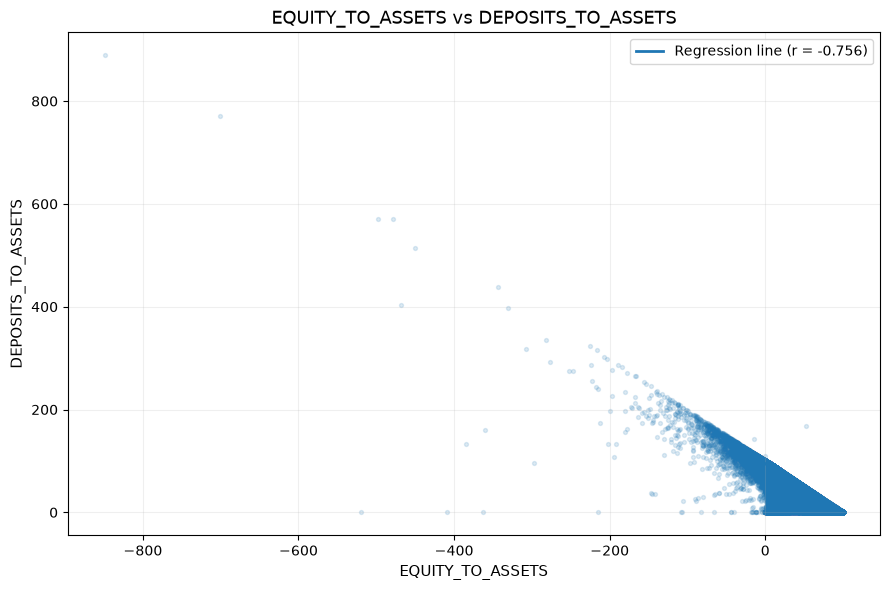

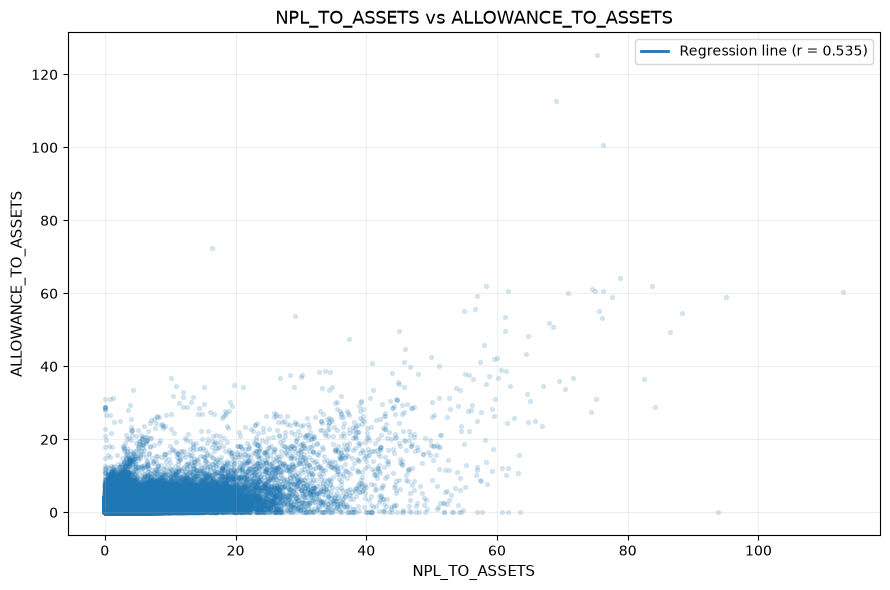

In [15]:
import matplotlib.pyplot as plt
import numpy as np

correlation_pairs = [
    ("EQUITY_TO_ASSETS", "DEPOSITS_TO_ASSETS"),
    ("NPL_TO_ASSETS", "ALLOWANCE_TO_ASSETS")
]

for x_col, y_col in correlation_pairs:

    # Select valid observations
    plot_data = (
        features
        .select([x_col, y_col])
        .drop_nulls()
        .filter(
            pl.col(x_col).is_finite() &
            pl.col(y_col).is_finite()
        )
    )

    # Convert to NumPy
    x = plot_data[x_col].to_numpy()
    y = plot_data[y_col].to_numpy()

    # Calculate Pearson correlation
    r = np.corrcoef(x, y)[0, 1]

    # Fit linear regression line
    slope, intercept = np.polyfit(x, y, 1)

    x_line = np.linspace(
        np.percentile(x, 1),
        np.percentile(x, 99),
        100
    )
    y_line = slope * x_line + intercept

    # Plot
    fig, ax = plt.subplots(figsize=(9, 6))

    ax.scatter(
        x, y,
        alpha=0.15,
        s=8
    )

    ax.plot(
        x_line,
        y_line,
        linewidth=2,
        label=f"Regression line (r = {r:.3f})"
    )

    ax.set_xlabel(x_col, fontsize=11)
    ax.set_ylabel(y_col, fontsize=11)

    ax.set_title(
        f"{x_col} vs {y_col}",
        fontsize=13
    )

    ax.legend()
    ax.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

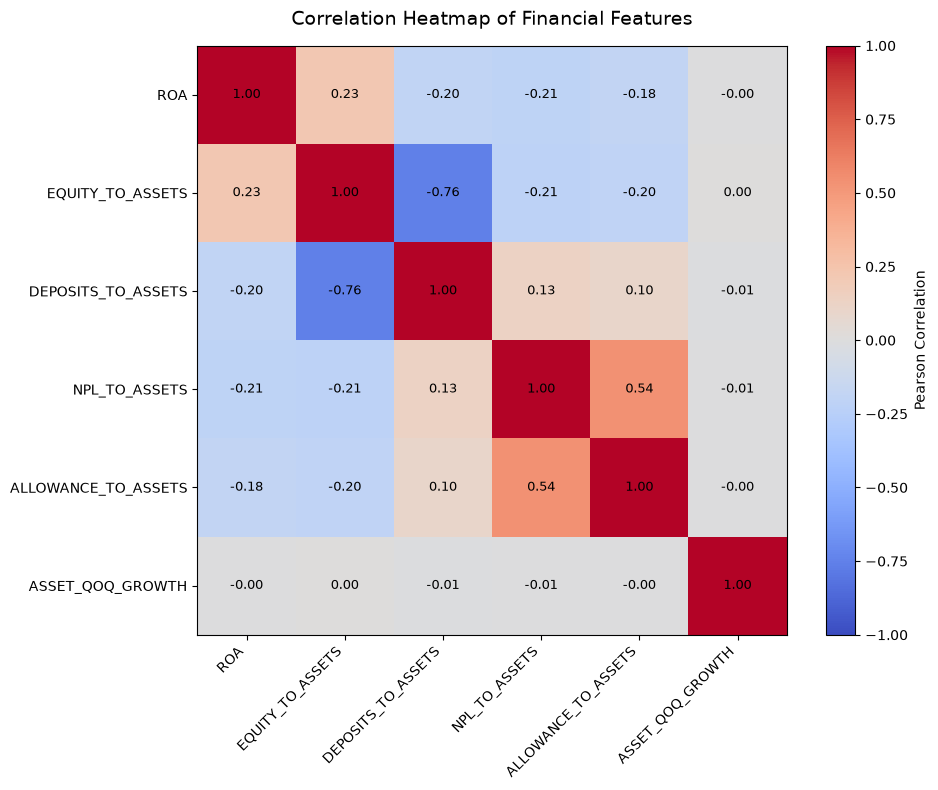

In [16]:
import matplotlib.pyplot as plt
import numpy as np

# Select financial features for correlation analysis
correlation_features = [
    "ROA",
    "EQUITY_TO_ASSETS",
    "DEPOSITS_TO_ASSETS",
    "NPL_TO_ASSETS",
    "ALLOWANCE_TO_ASSETS",
    "ASSET_QOQ_GROWTH"
]

# Calculate Pearson correlation matrix
correlation_matrix = (
    features
    .select(correlation_features)
    .to_pandas()
    .corr(method="pearson")
)

# Create heatmap
fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

# Add feature labels
ax.set_xticks(range(len(correlation_features)))
ax.set_yticks(range(len(correlation_features)))

ax.set_xticklabels(
    correlation_features,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(correlation_features)

# Add correlation values
for i in range(len(correlation_features)):
    for j in range(len(correlation_features)):
        value = correlation_matrix.iloc[i, j]

        ax.text(
            j,
            i,
            f"{value:.2f}",
            ha="center",
            va="center",
            color="black",
            fontsize=9
        )

# Title and color bar
ax.set_title(
    "Correlation Heatmap of Financial Features",
    fontsize=14,
    pad=15
)

fig.colorbar(
    im,
    ax=ax,
    label="Pearson Correlation"
)

plt.tight_layout()

# Save figure
fig.savefig(
    figure_dir / "03_correlation_heatmap_financial_features.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

In [17]:
from pathlib import Path

figure_dir = Path("../outputs/figures")
figure_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figure_dir / "feature_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

### Feature Correlation Analysis

Pearson correlation was used to examine linear relationships among the financial features.

The strongest relationship was observed between EQUITY_TO_ASSETS and DEPOSITS_TO_ASSETS, with a correlation coefficient of -0.756. This indicates a strong negative linear association between the two capital structure indicators.

NPL_TO_ASSETS and ALLOWANCE_TO_ASSETS also showed a moderate positive correlation of 0.535, which is consistent with the relationship between asset quality deterioration and loan loss provisioning.

The remaining financial features generally exhibited weak linear correlations. ASSET_QOQ_GROWTH showed almost no linear correlation with the other variables.

All six features were retained at this stage because they represent different aspects of bank financial conditions. Multicollinearity will be examined further during model development, particularly for Logistic Regression.

In [18]:
# 1. Các cột chỉ dùng để định danh hoặc theo dõi thời gian
identifier_cols = [
    "CERT",
    "ID",
    "REPDTE",
    "REPORT_DATE",
    "REPORT_Q_INDEX",
    "YEAR",
    "QUARTER"
]

# 2. Các cột liên quan đến kết quả thất bại ngân hàng
target_cols = [
    "FIRST_FAILURE_DATE",
    "FAILURE_Q_INDEX",
    "FAILURE_LABEL",
    "FINAL_LABEL",
    "IS_MERGER_CENSORED"
]

# 3. Các biến tài chính và biến được tạo ra
candidate_features = [
    col for col in features.columns
    if col not in identifier_cols + target_cols
]

print("IDENTIFIER / TIME COLUMNS:")
print(identifier_cols)

print("\nTARGET / OUTCOME COLUMNS:")
print(target_cols)

print("\nCANDIDATE PREDICTOR FEATURES:")
print(candidate_features)

print("\nNumber of candidate features:", len(candidate_features))

IDENTIFIER / TIME COLUMNS:
['CERT', 'ID', 'REPDTE', 'REPORT_DATE', 'REPORT_Q_INDEX', 'YEAR', 'QUARTER']

TARGET / OUTCOME COLUMNS:
['FIRST_FAILURE_DATE', 'FAILURE_Q_INDEX', 'FAILURE_LABEL', 'FINAL_LABEL', 'IS_MERGER_CENSORED']

CANDIDATE PREDICTOR FEATURES:
['NCLNLS', 'LNATRES', 'ROA', 'ASSET', 'RBC1AAJ', 'NETINC', 'EQ', 'DEP', 'PREV_NETINC_YTD', 'PREV_QUARTER', 'QUARTERLY_NETINC', 'LOG_ASSET', 'EQUITY_TO_ASSETS', 'DEPOSITS_TO_ASSETS', 'NEGATIVE_NCLNLS_FLAG', 'NEGATIVE_LNATRES_FLAG', 'NPL_TO_ASSETS', 'ALLOWANCE_TO_ASSETS', 'ASSET_QOQ_GROWTH', 'EQUITY_RATIO_CHANGE', 'ROA_CHANGE', 'NPL_RATIO_CHANGE', 'ALLOWANCE_RATIO_CHANGE', 'EXTREME_ASSET_GROWTH_FLAG']

Number of candidate features: 24


In [19]:
print("IDENTIFIER / TIME COLUMNS:")
print(identifier_cols)

print("\nTARGET / OUTCOME COLUMNS:")
print(target_cols)

print("\nCANDIDATE PREDICTOR FEATURES:")
print(candidate_features)

print("\nNumber of candidate features:", len(candidate_features))

IDENTIFIER / TIME COLUMNS:
['CERT', 'ID', 'REPDTE', 'REPORT_DATE', 'REPORT_Q_INDEX', 'YEAR', 'QUARTER']

TARGET / OUTCOME COLUMNS:
['FIRST_FAILURE_DATE', 'FAILURE_Q_INDEX', 'FAILURE_LABEL', 'FINAL_LABEL', 'IS_MERGER_CENSORED']

CANDIDATE PREDICTOR FEATURES:
['NCLNLS', 'LNATRES', 'ROA', 'ASSET', 'RBC1AAJ', 'NETINC', 'EQ', 'DEP', 'PREV_NETINC_YTD', 'PREV_QUARTER', 'QUARTERLY_NETINC', 'LOG_ASSET', 'EQUITY_TO_ASSETS', 'DEPOSITS_TO_ASSETS', 'NEGATIVE_NCLNLS_FLAG', 'NEGATIVE_LNATRES_FLAG', 'NPL_TO_ASSETS', 'ALLOWANCE_TO_ASSETS', 'ASSET_QOQ_GROWTH', 'EQUITY_RATIO_CHANGE', 'ROA_CHANGE', 'NPL_RATIO_CHANGE', 'ALLOWANCE_RATIO_CHANGE', 'EXTREME_ASSET_GROWTH_FLAG']

Number of candidate features: 24


In [20]:
primary_features = [
    "ROA",
    "LOG_ASSET",
    "EQUITY_TO_ASSETS",
    "DEPOSITS_TO_ASSETS",
    "NPL_TO_ASSETS",
    "ALLOWANCE_TO_ASSETS",
    "ASSET_QOQ_GROWTH",
    "EQUITY_RATIO_CHANGE",
    "ROA_CHANGE",
    "NPL_RATIO_CHANGE",
    "ALLOWANCE_RATIO_CHANGE",
    "NEGATIVE_NCLNLS_FLAG",
    "NEGATIVE_LNATRES_FLAG",
    "EXTREME_ASSET_GROWTH_FLAG",
    "QUARTERLY_NETINC"
]

print("Number of primary candidate features:", len(primary_features))
print(primary_features)

Number of primary candidate features: 15
['ROA', 'LOG_ASSET', 'EQUITY_TO_ASSETS', 'DEPOSITS_TO_ASSETS', 'NPL_TO_ASSETS', 'ALLOWANCE_TO_ASSETS', 'ASSET_QOQ_GROWTH', 'EQUITY_RATIO_CHANGE', 'ROA_CHANGE', 'NPL_RATIO_CHANGE', 'ALLOWANCE_RATIO_CHANGE', 'NEGATIVE_NCLNLS_FLAG', 'NEGATIVE_LNATRES_FLAG', 'EXTREME_ASSET_GROWTH_FLAG', 'QUARTERLY_NETINC']


In [21]:
# Check whether selected features exist in the dataset
missing_columns = [
    col for col in primary_features
    if col not in features.columns
]

if missing_columns:
    print("Missing columns:", missing_columns)
else:
    print("All primary features exist in the dataset.")

# Check data types
print(features.select(primary_features).schema)

All primary features exist in the dataset.
Schema({'ROA': Float64, 'LOG_ASSET': Float64, 'EQUITY_TO_ASSETS': Float64, 'DEPOSITS_TO_ASSETS': Float64, 'NPL_TO_ASSETS': Float64, 'ALLOWANCE_TO_ASSETS': Float64, 'ASSET_QOQ_GROWTH': Float64, 'EQUITY_RATIO_CHANGE': Float64, 'ROA_CHANGE': Float64, 'NPL_RATIO_CHANGE': Float64, 'ALLOWANCE_RATIO_CHANGE': Float64, 'NEGATIVE_NCLNLS_FLAG': Boolean, 'NEGATIVE_LNATRES_FLAG': Boolean, 'EXTREME_ASSET_GROWTH_FLAG': Boolean, 'QUARTERLY_NETINC': Float64})


In [22]:
# Full missing-value summary for the 15 candidate features

missing_summary = (
    features
    .select([
        pl.col(col).null_count().alias(col)
        for col in primary_features
    ])
    .to_dicts()[0]
)

total_rows = features.height

for col, missing_count in missing_summary.items():
    missing_rate = missing_count / total_rows * 100

    print(
        f"{col:<30} "
        f"Missing: {missing_count:>8,} "
        f"({missing_rate:.4f}%)"
    )

ROA                            Missing:        0 (0.0000%)
LOG_ASSET                      Missing:        0 (0.0000%)
EQUITY_TO_ASSETS               Missing:    4,080 (0.2452%)
DEPOSITS_TO_ASSETS             Missing:        1 (0.0001%)
NPL_TO_ASSETS                  Missing:    2,502 (0.1504%)
ALLOWANCE_TO_ASSETS            Missing:    4,090 (0.2458%)
ASSET_QOQ_GROWTH               Missing:   24,085 (1.4475%)
EQUITY_RATIO_CHANGE            Missing:   28,120 (1.6900%)
ROA_CHANGE                     Missing:   24,085 (1.4475%)
NPL_RATIO_CHANGE               Missing:   26,575 (1.5972%)
ALLOWANCE_RATIO_CHANGE         Missing:   28,136 (1.6910%)
NEGATIVE_NCLNLS_FLAG           Missing:        0 (0.0000%)
NEGATIVE_LNATRES_FLAG          Missing:        0 (0.0000%)
EXTREME_ASSET_GROWTH_FLAG      Missing:        0 (0.0000%)
QUARTERLY_NETINC               Missing:    9,896 (0.5948%)


In [23]:
features = features.with_columns(
    pl.when(
        (pl.col("ASSET") > 0)
        & pl.col("QUARTERLY_NETINC").is_not_null()
    )
    .then(
        pl.col("QUARTERLY_NETINC")
        / pl.col("ASSET")
        * 100
    )
    .otherwise(None)
    .alias("QUARTERLY_NETINC_TO_ASSETS")
)

# Check the new feature
features.select(
    [
        "CERT",
        "REPORT_DATE",
        "ASSET",
        "QUARTERLY_NETINC",
        "QUARTERLY_NETINC_TO_ASSETS"
    ]
).head(10)

CERT,REPORT_DATE,ASSET,QUARTERLY_NETINC,QUARTERLY_NETINC_TO_ASSETS
i64,date,i64,f64,f64
8,1984-03-31,444738,770.0,0.173136
8,1984-06-30,420993,1130.0,0.268413
8,1984-09-30,552359,2678.0,0.48483
8,1984-12-31,586498,2047.0,0.349021
8,1985-03-31,561691,1739.0,0.309601
8,1985-06-30,635360,4216.0,0.663561
8,1985-09-30,635360,0.0,0.0
8,1985-12-31,664949,1322.0,0.198812
8,1986-03-31,623450,2046.0,0.328174


In [24]:
features.select(
    [
        pl.col("QUARTERLY_NETINC_TO_ASSETS").null_count()
        .alias("MISSING_COUNT"),

        pl.col("QUARTERLY_NETINC_TO_ASSETS").mean()
        .alias("MEAN"),

        pl.col("QUARTERLY_NETINC_TO_ASSETS").median()
        .alias("MEDIAN"),

        pl.col("QUARTERLY_NETINC_TO_ASSETS").min()
        .alias("MIN"),

        pl.col("QUARTERLY_NETINC_TO_ASSETS").max()
        .alias("MAX")
    ]
)

MISSING_COUNT,MEAN,MEDIAN,MIN,MAX
u32,f64,f64,f64,f64
9896,0.662078,0.239354,-32622.772277,802200.0


In [25]:
# Distribution analysis of quarterly net income to assets

income_ratio_stats = (
    features
    .select(
        pl.col("QUARTERLY_NETINC_TO_ASSETS")
        .filter(pl.col("QUARTERLY_NETINC_TO_ASSETS").is_finite())
        .quantile(0.01).alias("P01"),

        pl.col("QUARTERLY_NETINC_TO_ASSETS")
        .filter(pl.col("QUARTERLY_NETINC_TO_ASSETS").is_finite())
        .quantile(0.05).alias("P05"),

        pl.col("QUARTERLY_NETINC_TO_ASSETS")
        .filter(pl.col("QUARTERLY_NETINC_TO_ASSETS").is_finite())
        .median().alias("P50"),

        pl.col("QUARTERLY_NETINC_TO_ASSETS")
        .filter(pl.col("QUARTERLY_NETINC_TO_ASSETS").is_finite())
        .quantile(0.95).alias("P95"),

        pl.col("QUARTERLY_NETINC_TO_ASSETS")
        .filter(pl.col("QUARTERLY_NETINC_TO_ASSETS").is_finite())
        .quantile(0.99).alias("P99")
    )
)

income_ratio_stats

P01,P05,P50,P95,P99
f64,f64,f64,f64,f64
-1.791169,-0.340006,0.239354,0.574163,1.210818


In [26]:
# 10 highest observations
highest_income_ratio = (
    features
    .filter(
        pl.col("QUARTERLY_NETINC_TO_ASSETS").is_finite()
    )
    .sort("QUARTERLY_NETINC_TO_ASSETS", descending=True)
    .select([
        "CERT",
        "REPORT_DATE",
        "ASSET",
        "QUARTERLY_NETINC",
        "QUARTERLY_NETINC_TO_ASSETS",
        "ROA"
    ])
    .head(10)
)

print("TOP 10 HIGHEST VALUES:")
display(highest_income_ratio)


# 10 lowest observations
lowest_income_ratio = (
    features
    .filter(
        pl.col("QUARTERLY_NETINC_TO_ASSETS").is_finite()
    )
    .sort("QUARTERLY_NETINC_TO_ASSETS")
    .select([
        "CERT",
        "REPORT_DATE",
        "ASSET",
        "QUARTERLY_NETINC",
        "QUARTERLY_NETINC_TO_ASSETS",
        "ROA"
    ])
    .head(10)
)

print("TOP 10 LOWEST VALUES:")
display(lowest_income_ratio)

TOP 10 HIGHEST VALUES:


CERT,REPORT_DATE,ASSET,QUARTERLY_NETINC,QUARTERLY_NETINC_TO_ASSETS,ROA
i64,date,i64,f64,f64,f64
19066,1997-12-31,1,8022.0,802200.0,4.90524
1596,2000-06-30,1495,14889.0,995.919732,131.064783
23761,1991-03-31,83233,320691.0,385.293093,51.134606
22314,1987-09-30,13498,42821.0,317.239591,23.10051
27291,1997-06-30,1,3.0,300.0,0.171811
90588,1992-06-30,215,607.0,282.325581,51.997684
26840,1989-03-31,4549,12169.0,267.509343,860.608204
24809,1995-12-31,10573,19258.0,182.143195,4.123641
1596,1998-09-30,38590,66113.0,171.321586,75.026377


TOP 10 LOWEST VALUES:


CERT,REPORT_DATE,ASSET,QUARTERLY_NETINC,QUARTERLY_NETINC_TO_ASSETS,ROA
i64,date,i64,f64,f64,f64
32611,2001-12-31,101,-32949.0,-32622.772277,-40.138157
18664,2010-03-31,107,-5440.0,-5084.11215,-761.904762
21960,2008-12-31,66,-1730.0,-2621.212121,0.0
33497,2017-12-31,8378,-106785.0,-1274.588207,-0.105743
34419,2001-06-30,1574,-12373.0,-786.086404,-99.352916
57936,2013-09-30,1103,-8522.0,-772.620127,-147.362127
5915,2006-06-30,1205,-5900.0,-489.626556,0.000559
26508,2013-12-31,4264,-15929.0,-373.569418,-7.84323
34167,2012-12-31,207,-695.0,-335.748792,-2.869648


NameError: name 'income_ratio_data' is not defined

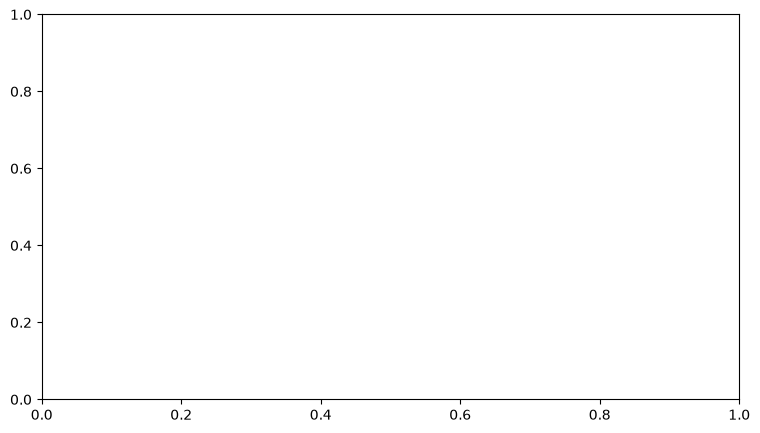

In [27]:
# Save full distribution
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(income_ratio_data, bins=100)
ax.set_xlabel("Quarterly Net Income to Assets (%)")
ax.set_ylabel("Frequency")
ax.set_title("Distribution of Quarterly Net Income to Assets")
ax.grid(alpha=0.2)

plt.tight_layout()

fig.savefig(
    figure_dir / "quarterly_net_income_to_assets_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# Save zoomed distribution (P01-P99)
p01, p99 = np.percentile(income_ratio_data, [1, 99])

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(income_ratio_data, bins=100, range=(p01, p99))
ax.set_xlabel("Quarterly Net Income to Assets (%)")
ax.set_ylabel("Frequency")
ax.set_title("Quarterly Net Income to Assets (P01-P99 Range)")
ax.grid(alpha=0.2)

plt.tight_layout()

fig.savefig(
    figure_dir / "quarterly_net_income_to_assets_zoomed.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

Distribution of Quarterly Net Income to Assets

The distribution is highly right-skewed, with most observations concentrated around zero and a small number of extremely large positive values. These extreme observations stretch the horizontal axis and make the central distribution difficult to interpret. Therefore, further percentile-based analysis and inspection of extreme observations are required before deciding whether this feature should be included in the predictive model.

In [ ]:
# Final primary feature candidates

primary_features = [
    "ROA",
    "LOG_ASSET",
    "EQUITY_TO_ASSETS",
    "DEPOSITS_TO_ASSETS",
    "NPL_TO_ASSETS",
    "ALLOWANCE_TO_ASSETS",
    "ASSET_QOQ_GROWTH",
    "EQUITY_RATIO_CHANGE",
    "ROA_CHANGE",
    "NPL_RATIO_CHANGE",
    "ALLOWANCE_RATIO_CHANGE",
    "NEGATIVE_NCLNLS_FLAG",
    "NEGATIVE_LNATRES_FLAG",
    "EXTREME_ASSET_GROWTH_FLAG"
]

print("Number of primary features:", len(primary_features))
print(primary_features)

# Confirm the exploratory feature is excluded
print(
    "\nQUARTERLY_NETINC_TO_ASSETS included:",
    "QUARTERLY_NETINC_TO_ASSETS" in primary_features
)

Number of primary features: 14
['ROA', 'LOG_ASSET', 'EQUITY_TO_ASSETS', 'DEPOSITS_TO_ASSETS', 'NPL_TO_ASSETS', 'ALLOWANCE_TO_ASSETS', 'ASSET_QOQ_GROWTH', 'EQUITY_RATIO_CHANGE', 'ROA_CHANGE', 'NPL_RATIO_CHANGE', 'ALLOWANCE_RATIO_CHANGE', 'NEGATIVE_NCLNLS_FLAG', 'NEGATIVE_LNATRES_FLAG', 'EXTREME_ASSET_GROWTH_FLAG']

QUARTERLY_NETINC_TO_ASSETS included: False


In [ ]:
# ============================================================
# AUDIT: CHECK PRIMARY FEATURE AVAILABILITY
# ============================================================

missing_primary_features = [
    col for col in primary_features
    if col not in features.columns
]

print("Number of primary features:", len(primary_features))
print("Missing primary features:", missing_primary_features)

print("\nPrimary feature data types:")
print(
    features.select(primary_features).schema
)

print("\nDuplicate feature names:")
print(
    len(primary_features) - len(set(primary_features))
)

Number of primary features: 15
Missing primary features: []

Primary feature data types:
Schema({'ROA': Float64, 'LOG_ASSET': Float64, 'EQUITY_TO_ASSETS': Float64, 'DEPOSITS_TO_ASSETS': Float64, 'NPL_TO_ASSETS': Float64, 'ALLOWANCE_TO_ASSETS': Float64, 'ASSET_QOQ_GROWTH': Float64, 'EQUITY_RATIO_CHANGE': Float64, 'ROA_CHANGE': Float64, 'NPL_RATIO_CHANGE': Float64, 'ALLOWANCE_RATIO_CHANGE': Float64, 'NEGATIVE_NCLNLS_FLAG': Boolean, 'NEGATIVE_LNATRES_FLAG': Boolean, 'EXTREME_ASSET_GROWTH_FLAG': Boolean, 'QUARTERLY_NETINC': Float64})

Duplicate feature names:
0


In [ ]:
print("CURRENT PRIMARY FEATURES:")
for i, col in enumerate(primary_features, start=1):
    print(f"{i}. {col}")

print("\nQUARTERLY_NETINC included:",
      "QUARTERLY_NETINC" in primary_features)

print("QUARTERLY_NETINC_TO_ASSETS included:",
      "QUARTERLY_NETINC_TO_ASSETS" in primary_features)

CURRENT PRIMARY FEATURES:
1. ROA
2. LOG_ASSET
3. EQUITY_TO_ASSETS
4. DEPOSITS_TO_ASSETS
5. NPL_TO_ASSETS
6. ALLOWANCE_TO_ASSETS
7. ASSET_QOQ_GROWTH
8. EQUITY_RATIO_CHANGE
9. ROA_CHANGE
10. NPL_RATIO_CHANGE
11. ALLOWANCE_RATIO_CHANGE
12. NEGATIVE_NCLNLS_FLAG
13. NEGATIVE_LNATRES_FLAG
14. EXTREME_ASSET_GROWTH_FLAG
15. QUARTERLY_NETINC

QUARTERLY_NETINC included: True
QUARTERLY_NETINC_TO_ASSETS included: False


### Assessment of Quarterly Net Income to Assets

The `QUARTERLY_NETINC_TO_ASSETS` variable was constructed to measure quarterly net income relative to total assets. However, its distribution is highly right-skewed, with a median of 0.2394% and a 99th percentile of 1.2108%.

Several extreme observations were identified, particularly among institutions with very small asset values. For example, one observation reported total assets of only USD 1 thousand and quarterly net income of USD 8,022 thousand, resulting in an unusually high ratio of 802,200%.

These observations indicate that the ratio can become unstable when total assets are very small. Furthermore, the dataset already contains ROA as an established profitability measure.

Therefore, `QUARTERLY_NETINC_TO_ASSETS` is retained for exploratory analysis but excluded from the primary predictive feature set. No observations are deleted or winsorized solely because of these extreme values.

In [ ]:
# Final missing-value audit for primary features

missing_audit = (
    features
    .select([
        pl.col(col).null_count().alias(col)
        for col in primary_features
    ])
    .to_dicts()[0]
)

total_rows = features.height

missing_audit_df = pl.DataFrame({
    "FEATURE": list(missing_audit.keys()),
    "MISSING_COUNT": list(missing_audit.values())
}).with_columns(
    (
        pl.col("MISSING_COUNT") / total_rows * 100
    ).round(4).alias("MISSING_RATE_PCT")
).sort("MISSING_RATE_PCT", descending=True)

display(missing_audit_df)

FEATURE,MISSING_COUNT,MISSING_RATE_PCT
str,i64,f64
"""ALLOWANCE_RATIO_CHANGE""",28136,1.691
"""EQUITY_RATIO_CHANGE""",28120,1.69
"""NPL_RATIO_CHANGE""",26575,1.5972
"""ASSET_QOQ_GROWTH""",24085,1.4475
"""ROA_CHANGE""",24085,1.4475
…,…,…
"""ROA""",0,0.0
"""LOG_ASSET""",0,0.0
"""NEGATIVE_NCLNLS_FLAG""",0,0.0


### Missing Value Treatment Strategy

Missing values were retained in the engineered feature dataset rather than being replaced automatically.

Missing values in financial ratios may result from unavailable source data or invalid calculation conditions. Missing values in temporal change variables mainly reflect the absence of valid consecutive quarterly observations.

Replacing these values with zero could incorrectly imply that no financial change occurred. Therefore, no global imputation was performed during feature engineering.

For predictive modeling, imputation will be considered only where necessary. Any imputation parameters will be estimated using the training dataset and then applied to validation and test datasets to prevent data leakage. Boolean indicator variables will be retained in their original format.

In [ ]:
# Check target availability
print("\nFINAL_LABEL distribution:")

final_label_distribution = (
    features
    .group_by("FINAL_LABEL")
    .agg(
        pl.len().alias("COUNT")
    )
    .sort("FINAL_LABEL", nulls_last=True)
)

display(final_label_distribution)


FINAL_LABEL distribution:


FINAL_LABEL,COUNT
i8,u32
0,1597644
1,10860
null,55372


In [ ]:
# [E3-v3] Notebook 03 chi DOC dataset chuan v3, khong xuat file moi.
assert feature_path.name == 'bank_quarter_features_v3.parquet', feature_path
assert feature_path.exists(), feature_path
print('Dataset (read-only):', feature_path)
print('Shape in memory:', features.shape)
print('Columns added in this notebook only (not saved):',
      [c for c in features.columns if c == 'QUARTERLY_NETINC_TO_ASSETS'])
